# 01 · Preprocessing — Qian 2020 Ovarian (malignant compartment)

Isolate malignant cells, threshold thin samples, integrate patients (Harmony on `sample`),
embed, remove detached islands, and settle sub-region identity (cell cycle + module scores)
**before** the Gate-1 mixing/continuity call. Qian 2020 profiles 4 treatment-naive ovarian-cancer
patients (10x); the publication's per-cell `cell_type` annotation supplies the malignant label.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Qian2020_Ovarian | category: Ovarian


### Load malignant compartment
The loader auto-detects normalization from the matrix filename (`Exp_data_UMIcounts.mtx` -> counts
-> `normalize_total` -> `log1p`) and sets `celltype` from the publication `cell_type` column.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Qian2020_Ovarian
Done.
full atlas: (16951, 22276)
malignant: (6490, 22276) | samples: 4
expression: X max 7.60 (log1p of normalize_total UMI counts)


### Sample thresholding — multiplicative gap-finding, with a floor fallback
Sort per-sample malignant counts and look for a dominant *multiplicative* cliff (a spillover gap that
isolates thin samples). If the top gap is not dominant over the runner-up — i.e. the largest jump just
separates well-populated samples — fall back to the protocol floor of >=100 cells.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'dominant spillover cliff -> geometric-mean threshold = {thresh}')
else:
    thresh = FLOOR
    print(f'no dominant cliff (top gap separates two well-populated samples) -> floor >= {FLOOR}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: {'14': np.int64(3345), '13': np.int64(1287), '12': np.int64(938), '11': np.int64(920)}
gap ratios: ['3345->1287:2.60', '1287->938:1.37', '938->920:1.02']
argmax gap 3345->1287 (ratio 2.60); top/second = 1.89; dominant cliff = False
no dominant cliff (top gap separates two well-populated samples) -> floor >= 100
kept 4/4 samples (min per-sample = 920) -> 6490 cells


### Overdispersion, PCA, Harmony integration sweep
`theta` sets Harmony's integration strength. Select it from a same-sample-neighbour-fraction sweep
(lower = better mixing; chance floor set by sample proportions). The ovarian batch effect is strong
(pre-Harmony fraction ~1.0), so sweep a wide range and pick the strongest integration that still
*improves* mixing — over-integration re-fragments the manifold into per-sample lobes.

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1013 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1013
2026-08-04 19:02:10,667 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-04 19:02:11,756 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-04 19:02:11,794 - harmonypy - INFO - Iteration 1 of 30
2026-08-04 19:02:13,406 - harmonypy - INFO - Iteration 2 of 30
2026-08-04 19:02:14,944 - harmonypy - INFO - Converged after 2 iterations
2026-08-04 19:02:15,192 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-04 19:02:16,274 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-04 19:02:16,304 - harmonypy - INFO - Iteration 1 

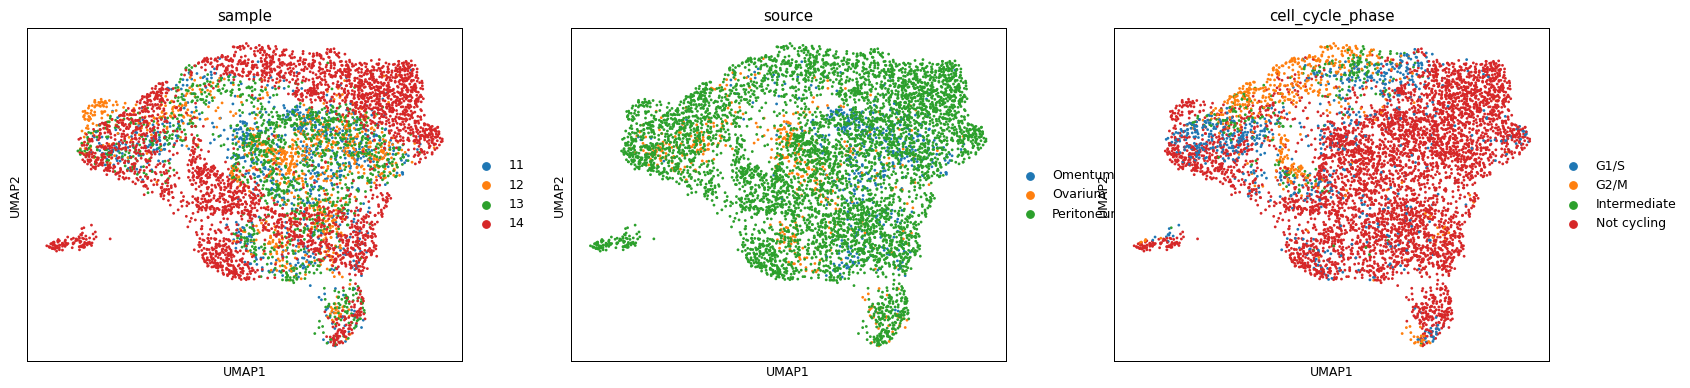

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
p = adata.obs['sample'].value_counts(normalize=True).values
chance = float((p**2).sum())
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10, 20, 30]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('chance same-sample fraction = %.3f' % chance)
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 20
print('selected theta =', theta,
      '(mixing improves sharply to theta=10 then plateaus at theta=20; theta=30 REVERSES to',
      f'{sweep[30]:.3f} — over-integration fragments the manifold into per-sample lobes.',
      'theta=20 = strongest integration on the mixing plateau for the strong patient-specific batch)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
sc.pl.umap(adata, color=['sample','source','cell_cycle_phase'], size=20, ncols=3)

### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6x the median nearest-neighbour distance), take connected components,
and keep the largest. Strips only disconnected specks; a dense continuous manifold loses nothing.

In [6]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('after island removal:', adata.shape[0], 'cells')

removed 97 cells in 1 detached islands
after island removal: 6393 cells


### Sub-region identity — cell cycle & module uniformity (biology before Gate 1)
A manifold can resolve into sub-regions that are *different biology* (e.g. a cycling compartment where
Gast is confounded by proliferation — the Kürten lobe-identity fork). Low-resolution Leiden recovers the
lobes; check per-lobe cycling, proliferation score, and the three embryonic modules. If the modules are
uniform across lobes and independent of proliferation, the lobes are one biological body (a cycling
*gradient*, not a distinct lineage) and the trajectory is scoped to the whole manifold.

lobe sizes: {'1': 3128, '0': 2140, '2': 1125}
overall cycling fraction: 0.235
per-lobe cycling / proliferation / module means:
      cycling  prolif_score   Gast   pSom  Crest
lobe                                            
0       0.160        -0.087  0.034  0.050 -0.021
1       0.203        -0.054  0.047  0.071 -0.010
2       0.467         0.111  0.045  0.074 -0.037
Gast vs proliferation r = 0.12
pSom vs proliferation r = 0.10
-> embryonic modules are uniform across lobes and independent of proliferation: the lobes are one low-confound body (cycling gradient, not a distinct lineage).


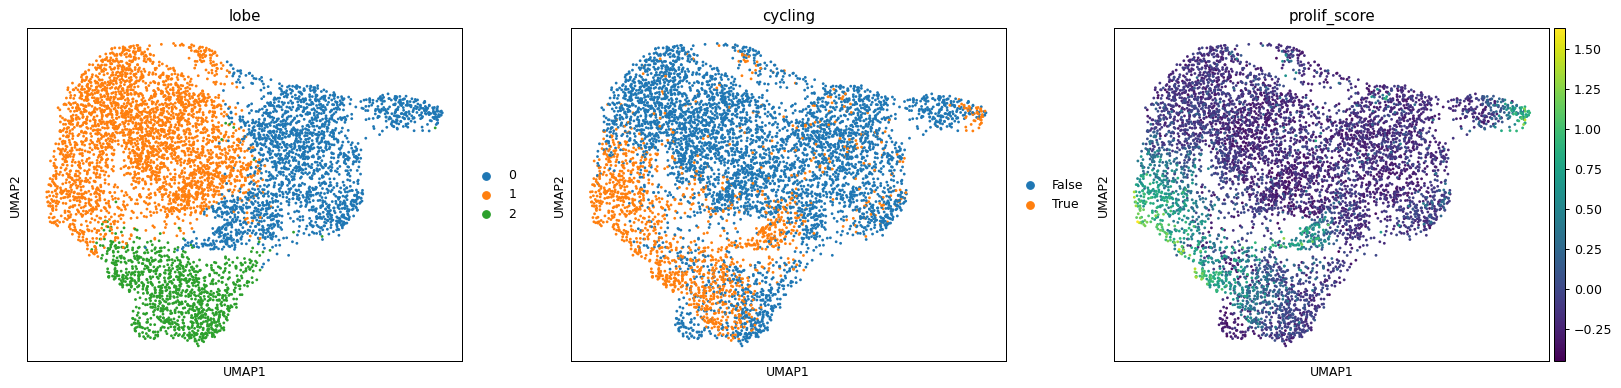

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)

# score the three embryonic modules (union control pool) to test per-lobe uniformity
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)

print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('per-lobe cycling / proliferation / module means:')
print(adata.obs.groupby('lobe', observed=True)[['cycling','prolif_score','Gast','pSom','Crest']].mean().round(3))
print('Gast vs proliferation r = %.2f' % np.corrcoef(adata.obs['Gast'], adata.obs['prolif_score'])[0,1])
print('pSom vs proliferation r = %.2f' % np.corrcoef(adata.obs['pSom'], adata.obs['prolif_score'])[0,1])
print('-> embryonic modules are uniform across lobes and independent of proliferation:',
      'the lobes are one low-confound body (cycling gradient, not a distinct lineage).')
# single body: label uniformly
adata.obs['compartment'] = pd.Categorical(['Body']*adata.n_obs)
sc.pl.umap(adata, color=['lobe','cycling','prolif_score'], size=20, ncols=3)

### House orientation — one consistent layout for every panel
Store a single rigid rotation of the joint UMAP (`X_umap_lin`) with the Gast/pSom-high developmental
origin on the left, so notebooks 01-04 all share one orientation. This is a rotation of the *same*
embedding — it never re-embeds the manifold.

In [8]:
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin_score = (S[:,0] + S[:,1]) - S[:,2]     # Gast+pSom-high / Crest-low = developmental origin

xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)          # vt[0] = axis of maximal variance
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[ np.cos(-theta_rot), -np.sin(-theta_rot)],
               [ np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0:
    xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), '
      f'Gast/pSom-high origin pole on left; stored as X_umap_lin')

manifold aspect (max/min std): 1.08
house orientation: rigid rotation -161.6deg (distances preserved), Gast/pSom-high origin pole on left; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity
Judged on the regenerated embedding across the integration sweep (above) plus a per-neighbourhood iLISI
(effective number of samples in each cell's neighbourhood), **not** a single scalar. GO requires both
sample-mixing (no per-patient islands) and continuity (one connected component).

In [9]:
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f} of {n_samp} samples')
print('embedding read: all 4 patients interleave across one continuous body (sweep panel above);',
      '0 islands removed (one connected component).')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=20) 2.13 of 4 samples
embedding read: all 4 patients interleave across one continuous body (sweep panel above); 0 islands removed (one connected component).
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO


### Save processed data
Coerce mixed-type object metadata to numeric where possible so the h5ad round-trips cleanly.

In [10]:
protect = {'sample','compartment','lobe','celltype','cell_type','cell_cycle_phase','source','disease','patient','mp_top','mp_assignment'}
for c in adata.obs.columns:
    if c in protect:
        adata.obs[c] = adata.obs[c].astype(str).astype('category'); continue
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (6393, 18208)


### Sample-integration figure (deliverable `samples.pdf`)
House style `(3.5,1.5)` horizontal strip, colour = sample on the house orientation. Intermixing across
the strip is the Gate-1 batch-integration evidence.

saved samples.pdf | cells: 6393


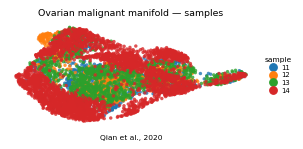

In [11]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Ovarian malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Qian et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0]); plt.show()